# Proyek Klasifikasi Gambar: German Traffic Sign Recognition Benchmark (GTSRB)
- **Nama:** Roy Aldonit Zidomi
- **Email:** zidomiroy@gmail.com
- **ID Dicoding:** royzidomi15

Notebook ini membangun model CNN untuk mengenali **43 jenis rambu lalu lintas** pada dataset GTSRB. Alurnya mengikuti templat proyek: memuat dan mengeksplorasi data, membagi data menjadi train, validation, dan test, melatih model `Sequential` (Conv2D + MaxPooling2D), mengevaluasi hasilnya, lalu mengekspor model ke format SavedModel, TF-Lite, dan TFJS serta mencoba inference dengan model TF-Lite.

## Import Semua Packages/Library yang Digunakan

Bagian ini menyiapkan lingkungan kerja dalam tiga sel:
- **Sel pemasangan** memasang `kagglehub` hanya bila belum tersedia (di Google Colab biasanya sudah ada), supaya notebook tetap bisa dijalankan di lingkungan lain.
- **Sel import** memuat semua library yang dipakai, dikelompokkan menurut fungsinya, lalu mencetak versi Python, TensorFlow, Keras, dan status GPU sebagai catatan lingkungan eksekusi.
- **Sel konfigurasi** mengumpulkan konstanta utama (seed, ukuran gambar, batch, epoch, learning rate, path keluaran) di satu tempat, agar mudah diubah dan tidak tersebar di banyak sel.

In [1]:
# kagglehub biasanya sudah terpasang di Colab; sel ini hanya memasangnya bila belum ada
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("kagglehub") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)

In [2]:
# ====== Library standar ======
import os
import shutil
import subprocess
import sys
import importlib.metadata as importlib_metadata
from pathlib import Path

# ====== Analisis data & visualisasi ======
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

# ====== Deep learning ======
import tensorflow as tf
import keras
from keras import layers, callbacks

# ====== Sumber dataset ======
import kagglehub

IN_COLAB = "google.colab" in sys.modules

print(f"Python      : {sys.version.split()[0]}")
print(f"TensorFlow  : {tf.__version__}")
print(f"Keras       : {keras.__version__}")
print(f"GPU         : {tf.config.list_physical_devices('GPU') or 'tidak ada (CPU)'}")
print(f"Lingkungan  : {'Google Colab' if IN_COLAB else 'Lokal'}")

Python      : 3.13.16
TensorFlow  : 2.21.0
Keras       : 3.13.2
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Lingkungan  : Google Colab


**Konfigurasi global.** Seed ditetapkan dengan `keras.utils.set_random_seed`, yang berlaku untuk `random`, NumPy, dan TensorFlow sekaligus. Dengan seed yang tetap, pengacakan pada shuffle, augmentasi, dan inisialisasi bobot menjadi konsisten, sehingga hasil lebih mudah direproduksi. Seed yang sama juga dipakai saat membagi data.

In [3]:
# ====== Konfigurasi global ======
SEED = 42
IMG_SIZE = 48            # resolusi asli 15-250 px diseragamkan menjadi 48x48 di pipeline data
BATCH_SIZE = 64
EPOCHS = 30              # batas atas; callback menghentikan training lebih awal
LEARNING_RATE = 1e-3     # learning rate awal optimizer Adam
VAL_FRACTION = 0.15      # porsi track dari folder Train yang dijadikan validation set
TARGET_ACCURACY = 0.95   # target akurasi train & test (saran bintang 5)
STOP_ACCURACY = 0.99     # ambang TargetAccuracyStop: akurasi train & validation untuk berhenti lebih awal

SUBMISSION_DIR = Path("submission")
SAVED_MODEL_DIR = SUBMISSION_DIR / "saved_model"
TFLITE_DIR = SUBMISSION_DIR / "tflite"
TFJS_DIR = SUBMISSION_DIR / "tfjs_model"
CHECKPOINT_PATH = "best_model.keras"

keras.utils.set_random_seed(SEED)   # seed untuk random, NumPy, dan TensorFlow

## Data Preparation

Persiapan data dilakukan dalam tiga tahap sesuai templat: **memuat** dataset dan memeriksa isinya (*Data Loading*), menyiapkan fungsi **preprocessing** dan augmentasi (*Data Preprocessing*), lalu **membagi** data menjadi train, validation, dan test (*Split Dataset*).

### Data Loading

Dataset yang dipakai adalah **GTSRB (German Traffic Sign Recognition Benchmark)**, yaitu kumpulan foto rambu lalu lintas Jerman yang terdiri atas 43 kelas. Versi yang digunakan adalah versi Kaggle (`meowmeowmeowmeowmeow/gtsrb-german-traffic-sign`). Dataset diunduh otomatis dengan `kagglehub`, sehingga notebook tidak bergantung pada path lokal mana pun.

- Folder `Train` berisi gambar latih yang dikelompokkan per kelas, dengan anotasi di `Train.csv`.
- Folder `Test` berisi gambar uji resmi, dengan label di `Test.csv`.
- Versi Kaggle juga memuat folder kembaran berhuruf kecil (`meta`, `test`, `train`) dengan jumlah item yang sama, seperti terlihat pada daftar isi di bawah. Notebook ini hanya memakai file yang terdaftar di kedua CSV tersebut.

Sitasi dataset: J. Stallkamp, M. Schlipsing, J. Salmen, C. Igel, "The German Traffic Sign Recognition Benchmark: A multi-class classification competition", IJCNN 2011.

In [4]:
# Unduh dataset GTSRB dari Kaggle (dataset publik, tidak perlu login)
DATASET_HANDLE = "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
dataset_root = Path(kagglehub.dataset_download(DATASET_HANDLE))

print("Lokasi dataset:", dataset_root)
for item in sorted(dataset_root.iterdir()):
    info = f"{sum(1 for _ in item.iterdir())} item" if item.is_dir() else f"{item.stat().st_size / 1e6:.2f} MB"
    print(f"  - {item.name:<10} {info}")

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Lokasi dataset: /kaggle/input/gtsrb-german-traffic-sign
  - Meta       45 item
  - Meta.csv   0.00 MB
  - Test       12631 item
  - Test.csv   0.43 MB
  - Train      43 item
  - Train.csv  1.94 MB
  - meta       45 item
  - test       12631 item
  - train      43 item


**Nama kelas.** File anotasi hanya menyimpan nomor kelas (`ClassId`). Daftar di bawah memetakan `ClassId` 0–42 ke nama rambu resmi GTSRB. Urutannya sama dengan indeks kelas, dan daftar inilah yang nanti ditulis ke `label.txt`.

In [5]:
GTSRB_CLASS_NAMES = [
    "Speed limit (20km/h)", "Speed limit (30km/h)", "Speed limit (50km/h)",
    "Speed limit (60km/h)", "Speed limit (70km/h)", "Speed limit (80km/h)",
    "End of speed limit (80km/h)", "Speed limit (100km/h)", "Speed limit (120km/h)",
    "No passing", "No passing for vehicles over 3.5 metric tons",
    "Right-of-way at the next intersection", "Priority road", "Yield", "Stop",
    "No vehicles", "Vehicles over 3.5 metric tons prohibited", "No entry",
    "General caution", "Dangerous curve to the left", "Dangerous curve to the right",
    "Double curve", "Bumpy road", "Slippery road", "Road narrows on the right",
    "Road work", "Traffic signals", "Pedestrians", "Children crossing",
    "Bicycles crossing", "Beware of ice/snow", "Wild animals crossing",
    "End of all speed and passing limits", "Turn right ahead", "Turn left ahead",
    "Ahead only", "Go straight or right", "Go straight or left", "Keep right",
    "Keep left", "Roundabout mandatory", "End of no passing",
    "End of no passing by vehicles over 3.5 metric tons",
]

**Membaca anotasi.** Label diambil dari kolom `ClassId` di `Train.csv` dan `Test.csv`, bukan dari urutan nama folder. Alasannya, nama folder `0, 1, 10, 11, ..., 2, 20, ...` yang diurutkan sebagai teks tidak sama dengan urutan angkanya, sehingga label bisa tertukar tanpa disadari.

Dari nama file latih (`<kelas>_<track>_<frame>.png`) diambil juga nomor **track**, yaitu rangkaian foto beruntun dari satu rambu fisik yang sama. Informasi ini dipakai saat membagi data. Sel ini juga memastikan setiap file yang tercantum di CSV benar-benar ada.

In [6]:
def resolve_path(root: Path, name: str) -> Path:
    """Cari file/folder `name` di root: nama persis dulu, lalu tanpa membedakan huruf besar/kecil."""
    exact = root / name
    if exact.exists():
        return exact
    for candidate in root.rglob("*"):
        if candidate.name.lower() == name.lower():
            return candidate
    raise FileNotFoundError(f"'{name}' tidak ditemukan di {root}")


def load_annotation(csv_name: str) -> pd.DataFrame:
    """Baca Train.csv / Test.csv dan ubah kolom Path menjadi path absolut."""
    csv_path = resolve_path(dataset_root, csv_name)
    table = pd.read_csv(csv_path)
    table["path"] = [str(csv_path.parent / p) for p in table["Path"]]
    table["label"] = table["ClassId"].astype(int)
    return table


train_full_df = load_annotation("Train.csv")
test_df = load_annotation("Test.csv")

# Nama file Train: <kelas>_<track>_<frame>.png -> token kedua dari belakang adalah nomor track.
# Satu track = foto beruntun dari rambu fisik yang sama (dipakai saat split agar tidak bocor).
train_full_df["track"] = [int(Path(p).stem.split("_")[-2]) for p in train_full_df["path"]]

missing = [p for p in pd.concat([train_full_df["path"], test_df["path"]]) if not os.path.exists(p)]
assert not missing, f"{len(missing)} file tidak ditemukan, contoh: {missing[:3]}"

NUM_CLASSES = train_full_df["label"].nunique()
assert sorted(train_full_df["label"].unique()) == list(range(NUM_CLASSES)), "ClassId harus 0..N-1"
CLASS_NAMES = GTSRB_CLASS_NAMES[:NUM_CLASSES]

print(f"Gambar folder Train: {len(train_full_df):,} | Gambar folder Test: {len(test_df):,} | Kelas: {NUM_CLASSES}")
print(f"Jumlah track per kelas: {train_full_df.groupby('label')['track'].nunique().min()} - "
      f"{train_full_df.groupby('label')['track'].nunique().max()}")
train_full_df[["path", "label", "track", "Width", "Height"]].head()

Gambar folder Train: 39,209 | Gambar folder Test: 12,630 | Kelas: 43
Jumlah track per kelas: 7 - 75


,path,label,track,Width,Height
0,/kaggle/input/gtsrb-german-traffic-sign/Train/...,20,0,27,26
1,/kaggle/input/gtsrb-german-traffic-sign/Train/...,20,0,28,27
2,/kaggle/input/gtsrb-german-traffic-sign/Train/...,20,0,29,26
3,/kaggle/input/gtsrb-german-traffic-sign/Train/...,20,0,28,27
4,/kaggle/input/gtsrb-german-traffic-sign/Train/...,20,0,28,26


**Jumlah gambar, jumlah kelas, dan resolusi asli.** Setiap gambar dibuka dengan PIL untuk membaca resolusi aslinya sekaligus memastikan file tidak korup. Ringkasannya dicetak sebagai baris penanda (`TOTAL_IMAGES`, `NUM_CLASSES`, `UNIQUE_RESOLUTIONS`), diikuti tabel per kelas yang berisi jumlah gambar, jumlah resolusi unik, dan rentang lebar gambar.

Pemeriksaan ini dilakukan pada gambar **asli**, sebelum ada preprocessing apa pun.

In [7]:
def inspect_images(paths) -> pd.DataFrame:
    """Baca resolusi (lebar, tinggi) tiap gambar dan cek apakah file bisa dibuka (tidak korup)."""
    records = []
    for path in paths:
        try:
            with Image.open(path) as img:
                width, height = img.size
                img.verify()
            records.append((width, height, True))
        except Exception:
            records.append((None, None, False))
    return pd.DataFrame(records, columns=["width", "height", "valid"]).astype(
        {"width": "Int64", "height": "Int64", "valid": bool})


image_cols = ["width", "height", "valid"]
train_full_df = train_full_df.drop(columns=image_cols, errors="ignore").join(inspect_images(train_full_df["path"]))
test_df = test_df.drop(columns=image_cols, errors="ignore").join(inspect_images(test_df["path"]))
all_images = pd.concat([train_full_df, test_df], ignore_index=True)
resolutions = all_images.loc[all_images["valid"], ["width", "height"]].astype(int)

print("=== RINGKASAN DATASET ===")
print(f"TOTAL_IMAGES: {len(all_images)}")
print(f"NUM_CLASSES: {NUM_CLASSES}")
print(f"UNIQUE_RESOLUTIONS: {len(resolutions.drop_duplicates())}")
print(f"Lebar  : {resolutions['width'].min()} - {resolutions['width'].max()} px")
print(f"Tinggi : {resolutions['height'].min()} - {resolutions['height'].max()} px")
print(f"Gambar korup/tidak terbaca: {int((~all_images['valid']).sum())}")

per_class = (train_full_df.assign(resolusi=train_full_df["width"].astype(str) + "x" + train_full_df["height"].astype(str))
             .groupby("label")
             .agg(jumlah_train=("path", "size"), resolusi_unik=("resolusi", "nunique"),
                  lebar_min=("width", "min"), lebar_max=("width", "max")))
per_class["jumlah_test"] = test_df["label"].value_counts().sort_index()
per_class.insert(0, "nama_kelas", CLASS_NAMES)
per_class

=== RINGKASAN DATASET ===
TOTAL_IMAGES: 51839
NUM_CLASSES: 43
UNIQUE_RESOLUTIONS: 3338
Lebar  : 25 - 266 px
Tinggi : 25 - 232 px
Gambar korup/tidak terbaca: 0


,nama_kelas,jumlah_train,resolusi_unik,lebar_min,lebar_max,jumlah_test
label,,,,,,
0,Speed limit (20km/h),210,163,27,144,60
1,Speed limit (30km/h),2220,641,25,164,720
2,Speed limit (50km/h),2250,538,25,171,750
3,Speed limit (60km/h),1410,393,25,151,450
4,Speed limit (70km/h),1980,453,25,148,660
5,Speed limit (80km/h),1860,429,25,161,630
6,End of speed limit (80km/h),420,187,25,98,150
7,Speed limit (100km/h),1440,379,25,176,450
8,Speed limit (120km/h),1410,372,25,147,450


**Visualisasi hasil eksplorasi.** Grafik batang menunjukkan jumlah gambar latih per kelas, dan scatter plot menunjukkan sebaran lebar × tinggi asli semua gambar. Setelah itu ditampilkan satu contoh gambar dari setiap kelas beserta resolusi aslinya.

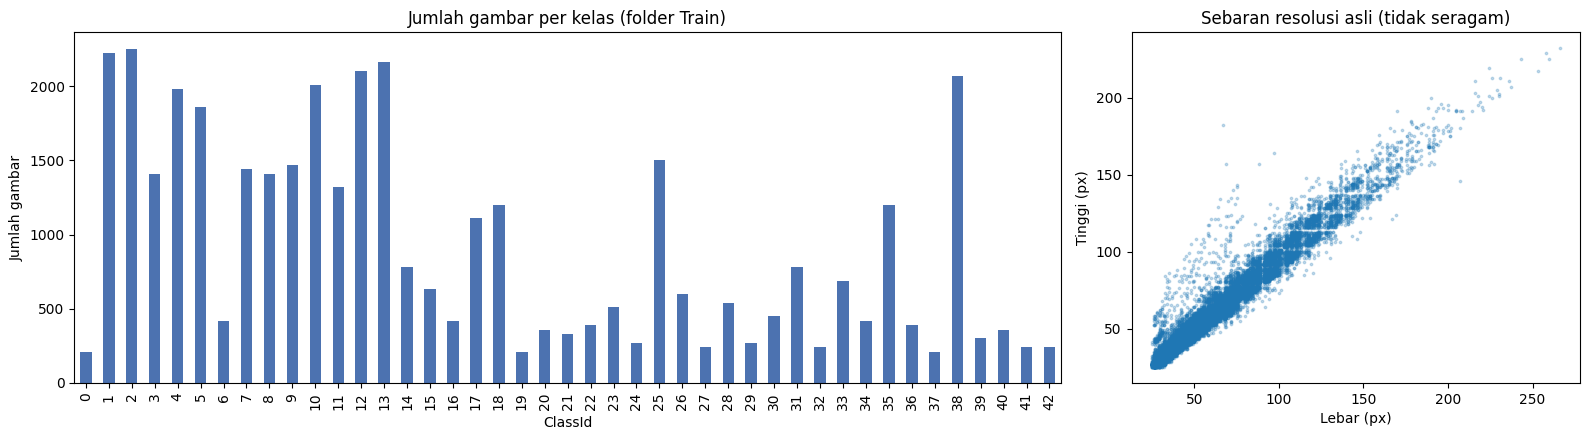

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

per_class["jumlah_train"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Jumlah gambar per kelas (folder Train)")
axes[0].set_xlabel("ClassId")
axes[0].set_ylabel("Jumlah gambar")

axes[1].scatter(resolutions["width"], resolutions["height"], s=3, alpha=0.25)
axes[1].set_title("Sebaran resolusi asli (tidak seragam)")
axes[1].set_xlabel("Lebar (px)")
axes[1].set_ylabel("Tinggi (px)")
plt.tight_layout()
plt.show()

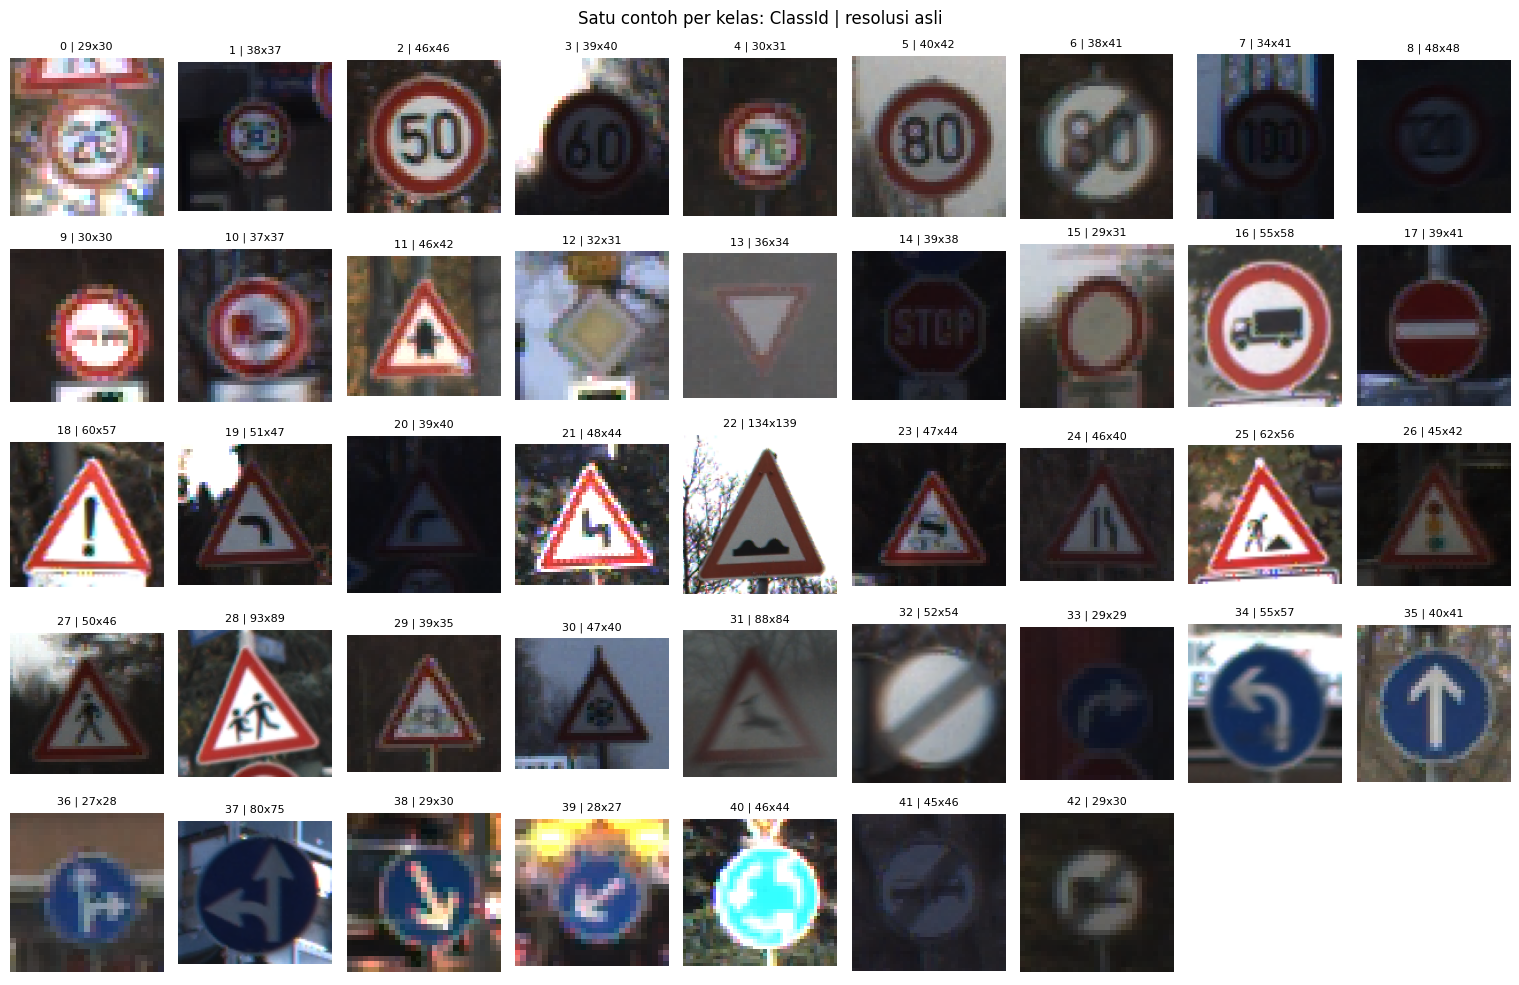

In [9]:
samples = train_full_df.groupby("label").sample(1, random_state=SEED)
n_cols = 9
n_rows = int(np.ceil(len(samples) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.7, n_rows * 2.0))
for ax in np.ravel(axes):
    ax.axis("off")
for ax, (_, row) in zip(np.ravel(axes), samples.iterrows()):
    with Image.open(row["path"]) as img:
        ax.imshow(img)
        ax.set_title(f"{row['label']} | {img.size[0]}x{img.size[1]}", fontsize=8)
plt.suptitle("Satu contoh per kelas: ClassId | resolusi asli")
plt.tight_layout()
plt.show()

**Hasil eksplorasi data** (angka dari output di atas):
- Dataset berisi **51.839 gambar** dalam **43 kelas**: 39.209 gambar di folder `Train` dan 12.630 gambar di folder `Test`. Tidak ada file yang korup.
- Jumlah gambar per kelas **tidak seimbang**. Kelas terkecil hanya memiliki 210 gambar latih (`ClassId` 0, 19, dan 37), sedangkan kelas terbesar memiliki 2.250 gambar (`ClassId` 2). Karena itu evaluasi nanti juga melihat precision dan recall per kelas, bukan hanya akurasi keseluruhan.
- Resolusi asli **tidak seragam**: ada 3.338 resolusi unik, dengan lebar 25–266 px dan tinggi 25–232 px, dan banyak gambar tidak persegi (lihat scatter plot). Deskripsi resmi GTSRB menyebut rentang 15–250 px, sedangkan angka di sini adalah hasil pengukuran langsung pada file versi Kaggle. Semua gambar diseragamkan ukurannya pada tahap preprocessing.
- Contoh gambar per kelas memperlihatkan variasi pencahayaan (beberapa sangat gelap), ketajaman, dan ukuran rambu. Variasi semacam inilah yang ditiru oleh augmentasi pada tahap berikutnya.

### Data Preprocessing

Gambar asli berukuran berbeda-beda, sedangkan CNN membutuhkan input berukuran tetap. Fungsi `load_and_resize` membaca file gambar sebagai RGB lalu mengubah ukurannya menjadi `IMG_SIZE` × `IMG_SIZE` (48 × 48 piksel). Ukuran ini dipilih karena gambar terkecil di dataset hanya 25 piksel (lihat ringkasan resolusi di atas): 48 piksel cukup untuk menyimpan detail rambu, dan model tetap cepat dilatih.

Nilai piksel sengaja dibiarkan pada rentang **0–255**. Normalisasi ke 0–1 dilakukan oleh layer `Rescaling` di dalam model (alasannya dijelaskan di bagian *Modelling*).

In [10]:
def load_and_resize(path: tf.Tensor) -> tf.Tensor:
    """Baca file -> RGB -> resize ke IMG_SIZE x IMG_SIZE (uint8, rentang 0-255)."""
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), antialias=True)
    return tf.cast(tf.clip_by_value(tf.round(image), 0, 255), tf.uint8)

**Augmentasi data.** Supaya model tidak sekadar menghafal data latih, setiap gambar latih diubah sedikit secara acak di setiap epoch: rotasi (±18°), zoom (±10%), pergeseran (±10%), dan kontras (±20%). Perubahan ini meniru kondisi nyata, yaitu rambu yang terfoto agak miring, lebih jauh atau dekat, tidak tepat di tengah, atau dengan pencahayaan berbeda.

- Augmentasi **hanya** dipakai untuk data train. Data validation dan test tidak diubah supaya hasil pengukurannya konsisten.
- **Tidak ada flip.** Membalik gambar dapat mengubah makna rambu, misalnya "Turn left ahead" menjadi "Turn right ahead" atau "Keep left" menjadi "Keep right", sehingga label gambar menjadi salah.

Sel di bawah juga menampilkan satu gambar asli (paling kiri) beserta tujuh hasil augmentasinya.

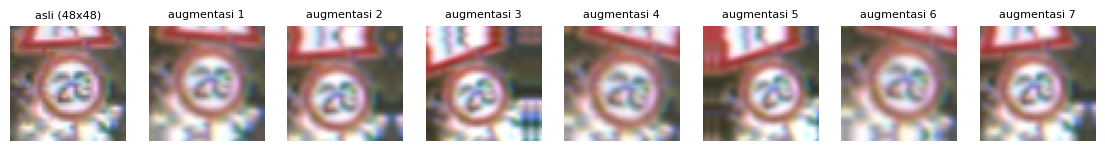

In [11]:
# Augmentasi HANYA untuk data latih. Tidak memakai flip karena membalik rambu
# dapat mengubah maknanya (mis. "Turn left ahead" <-> "Turn right ahead").
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.05, seed=SEED),          # +-18 derajat
    layers.RandomZoom(0.10, seed=SEED),
    layers.RandomTranslation(0.10, 0.10, seed=SEED),
    layers.RandomContrast(0.20, seed=SEED),
], name="data_augmentation")

example = load_and_resize(tf.constant(samples.iloc[0]["path"]))
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for i, ax in enumerate(axes):
    shown = example if i == 0 else data_augmentation(tf.cast(example, tf.float32)[None, ...], training=True)[0]
    ax.imshow(tf.cast(shown, tf.uint8))
    ax.set_title(f"asli ({IMG_SIZE}x{IMG_SIZE})" if i == 0 else f"augmentasi {i}", fontsize=8)
    ax.axis("off")
plt.show()

#### Split Dataset

Data dibagi menjadi tiga subset yang tidak saling beririsan:
- **Train** dan **validation** berasal dari folder `Train`. Sekitar 15% *track* dari setiap kelas dijadikan validation, sisanya train.
- **Test** memakai folder `Test` resmi dengan label dari `Test.csv`. Data ini tidak pernah dilihat model selama training.

**Kenapa dibagi per track, bukan per gambar?** Satu track berisi sekitar 30 foto beruntun dari satu rambu fisik yang sama, sehingga gambar di dalamnya sangat mirip. Jika data dibagi acak per gambar, foto dari rambu yang sama akan masuk ke train dan validation sekaligus (*data leakage*), dan akurasi validation akan tampak lebih tinggi daripada kemampuan model yang sebenarnya. Dengan memasukkan satu track utuh ke satu subset saja, data validation benar-benar berisi rambu yang belum pernah dilihat model.

Sel di bawah juga memeriksa bahwa tidak ada file yang muncul di dua subset, lalu mencetak jumlah dan persentase tiap subset.

In [12]:
def split_by_track(df: pd.DataFrame, val_fraction: float, seed: int = SEED):
    """Bagi data folder Train menjadi train/validation per kelas berdasarkan track.

    Satu track berisi foto beruntun dari rambu fisik yang sama, jadi satu track utuh
    dimasukkan ke satu subset saja untuk mencegah kebocoran data (data leakage).
    """
    rng = np.random.default_rng(seed)
    groups = df["label"].astype(str) + "_" + df["track"].astype(str)
    val_groups = set()
    for label, group in df.groupby("label"):
        tracks = np.sort(group["track"].unique())
        rng.shuffle(tracks)
        n_val = max(1, int(round(len(tracks) * val_fraction)))
        val_groups.update(f"{label}_{t}" for t in tracks[:n_val])
    is_val = groups.isin(val_groups).values
    return df[~is_val].reset_index(drop=True), df[is_val].reset_index(drop=True)


train_df, val_df = split_by_track(train_full_df, VAL_FRACTION)

# Pastikan tidak ada gambar yang sama di dua subset
assert not set(train_df["path"]) & set(val_df["path"])
assert not set(train_df["path"]) & set(test_df["path"])

total = len(train_df) + len(val_df) + len(test_df)
split_summary = pd.DataFrame({"jumlah_gambar": [len(train_df), len(val_df), len(test_df)]},
                             index=["train", "validation", "test"])
split_summary["persentase"] = (split_summary["jumlah_gambar"] / total * 100).round(2)
print(split_summary.to_string())
print(f"SPLIT_COUNTS: train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")

            jumlah_gambar  persentase
train               33359       64.35
validation           5850       11.28
test                12630       24.36
SPLIT_COUNTS: train=33359, val=5850, test=12630


**Hasil split** (lihat tabel di atas): train 33.359 gambar (64,35%), validation 5.850 gambar (11,28%), dan test 12.630 gambar (24,36%). Kedua pemeriksaan irisan lolos, jadi tidak ada gambar yang muncul di dua subset.

**Pipeline `tf.data`.** Setiap subset diubah menjadi `tf.data.Dataset` dengan urutan: baca dan resize → `cache` → `batch` → `prefetch`. `cache` menyimpan hasil resize di memori agar epoch berikutnya tidak perlu membaca file lagi, dan `prefetch` menyiapkan batch berikutnya selagi model sedang dilatih. Khusus data train ditambahkan `shuffle` (sebelum `batch`) dan augmentasi (sesudah `batch`).

`train_eval_ds` berisi data train yang sama, tetapi **tanpa** shuffle dan augmentasi. Dataset ini dipakai di bagian evaluasi untuk mengukur akurasi train akhir.

In [13]:
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(df: pd.DataFrame, training: bool = False) -> tf.data.Dataset:
    """Pipeline tf.data: baca -> resize -> cache -> (shuffle + augmentasi) -> batch -> prefetch."""
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values.astype("int32")))
    ds = ds.map(lambda p, y: (load_and_resize(p), y), num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(tf.cast(x, tf.float32), training=True), y),
                    num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)
train_eval_ds = make_dataset(train_df)   # tanpa augmentasi: untuk mengukur akurasi training akhir

images, labels = next(iter(train_ds))
print("Bentuk batch :", images.shape, labels.shape)
print("Rentang piksel:", float(tf.reduce_min(images)), "-", float(tf.reduce_max(images)))

Bentuk batch : (64, 48, 48, 3) (64,)
Rentang piksel: 0.0 - 255.0


## Modelling

Model dibangun dari nol dengan `keras.Sequential`. Susunannya:
- **`Rescaling(1/255)`** mengubah piksel 0–255 menjadi 0–1. Layer ini sengaja ditaruh **di dalam model** supaya model hasil ekspor (SavedModel, TF-Lite, TFJS) langsung menerima piksel mentah. Pemakai model tidak perlu mengingat langkah normalisasi, dan preprocessing saat inference pasti sama dengan saat training.
- **Tiga blok konvolusi** dengan 32, 64, dan 128 filter. Setiap `Conv2D` diikuti `BatchNormalization`, dan setiap blok ditutup `MaxPooling2D` serta `Dropout`. `Conv2D` mengekstrak pola visual (tepi, bentuk, simbol), `BatchNormalization` menstabilkan training, `MaxPooling2D` memperkecil ukuran peta fitur, dan `Dropout` mengurangi overfitting.
- **Bagian klasifikasi**: `Flatten` → `Dense(256)` (diikuti `BatchNormalization` dan `Dropout`) → `Dense` beraktivasi softmax yang menghasilkan probabilitas untuk setiap kelas.

Model dikompilasi dengan optimizer Adam dan loss `sparse_categorical_crossentropy`, karena label berupa bilangan bulat (`ClassId`), bukan one-hot.

In [14]:
def build_model(num_classes: int) -> keras.Sequential:
    """CNN Sequential: blok Conv2D + MaxPooling2D, lalu Dense untuk klasifikasi."""
    model = keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image"),
        layers.Rescaling(1.0 / 255),              # normalisasi di dalam model -> input mentah 0-255

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.2),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.3),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.4),

        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ], name="gtsrb_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


model = build_model(NUM_CLASSES)
model.summary()

Model: "gtsrb_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,05

 Total params: 1,332,683 (5.08 MB)

 Trainable params: 1,331,531 (5.08 MB)

 Non-trainable params: 1,152 (4.50 KB)

**Callback.** Empat callback mengatur training secara otomatis:
- **`TargetAccuracyStop`** (callback kustom) menghentikan training begitu akurasi train dan validation sama-sama mencapai `STOP_ACCURACY`, supaya waktu tidak terbuang setelah target tercapai.
- **`ModelCheckpoint`** menyimpan model setiap kali `val_accuracy` membaik, sehingga yang dipakai nanti adalah model terbaik, bukan model dari epoch terakhir.
- **`EarlyStopping`** menghentikan training bila `val_loss` tidak membaik selama 6 epoch (tanda model mulai overfitting) dan mengembalikan bobot terbaik.
- **`ReduceLROnPlateau`** menurunkan learning rate menjadi setengahnya bila `val_loss` tidak membaik selama 2 epoch, agar model bisa belajar dengan langkah yang lebih halus.

In [15]:
class TargetAccuracyStop(callbacks.Callback):
    """Callback kustom: hentikan training saat akurasi train dan validasi sudah >= target."""

    def __init__(self, target: float = 0.99):
        super().__init__()
        self.target = target

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        acc, val_acc = logs.get("accuracy", 0.0), logs.get("val_accuracy", 0.0)
        if acc >= self.target and val_acc >= self.target:
            print(f"\n[TargetAccuracyStop] epoch {epoch + 1}: accuracy={acc:.4f}, "
                  f"val_accuracy={val_acc:.4f} >= {self.target:.0%} -> training dihentikan")
            self.model.stop_training = True


training_callbacks = [
    TargetAccuracyStop(target=STOP_ACCURACY),
    callbacks.ModelCheckpoint(CHECKPOINT_PATH, monitor="val_accuracy", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]

**Training.** Model dilatih dengan data train (yang diaugmentasi) dan dipantau dengan data validation di setiap epoch. `EPOCHS` hanya batas atas, karena callback dapat menghentikan training lebih awal. Setelah training selesai, model dengan `val_accuracy` terbaik dimuat kembali dari checkpoint sebagai `best_model`. Model inilah yang dievaluasi dan diekspor.

In [16]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=training_callbacks,
    verbose=2,
)

best_model = keras.models.load_model(CHECKPOINT_PATH)   # bobot dengan val_accuracy terbaik
print("Model terbaik dimuat dari", CHECKPOINT_PATH)

Epoch 1/30

Epoch 1: val_accuracy improved from None to 0.68000, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
522/522 - 73s - 139ms/step - accuracy: 0.5157 - loss: 1.7472 - val_accuracy: 0.6800 - val_loss: 0.9951 - learning_rate: 0.0010
Epoch 2/30

Epoch 2: val_accuracy improved from 0.68000 to 0.92274, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
522/522 - 23s - 44ms/step - accuracy: 0.8525 - loss: 0.4747 - val_accuracy: 0.9227 - val_loss: 0.4480 - learning_rate: 0.0010
Epoch 3/30

Epoch 3: val_accuracy improved from 0.92274 to 0.96513, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
522/522 - 40s - 77ms/step - accuracy: 0.9281 - loss: 0.2327 - val_accuracy: 0.9651 - val_loss: 0.1331 - learning_rate: 0.0010
Epoch 4/30

Epoch 4: val_accuracy improved from 0.96513 to 0.98547, saving model to best_model.keras

Epoch 4: finished saving model to best_model.keras
522/522 - 23

**Hasil training** (lihat log di atas):
- Training berhenti pada **epoch 14 dari maksimal 30**. Yang menghentikannya adalah `TargetAccuracyStop`, karena `accuracy` 0,9917 dan `val_accuracy` 0,9962 sudah melewati 99%.
- `ReduceLROnPlateau` menurunkan learning rate dari 0,001 menjadi 0,0005 pada epoch 12, setelah `val_loss` tidak membaik selama dua epoch.
- `val_accuracy` sempat turun ke 0,9513 pada epoch 7, lalu pulih ke 0,9915 pada epoch 8. Penurunan sesaat ini tidak berlanjut, dan model terbaik tetap dipilih lewat checkpoint.
- `ModelCheckpoint` terakhir menyimpan model pada epoch 14, yaitu epoch dengan `val_accuracy` tertinggi (0,9962). Model itulah yang dimuat sebagai `best_model`.

## Evaluasi dan Visualisasi

Evaluasi memakai `best_model` dan dilakukan dalam tiga langkah: grafik akurasi dan loss selama training, akurasi akhir pada ketiga subset, lalu laporan per kelas dan confusion matrix pada test set.

**Grafik akurasi dan loss.** Kurva train dan validation yang bergerak berdekatan menandakan model belajar dengan baik. Jika kurva validation menjauh dari kurva train, model mulai overfitting. Garis putus-putus menandai epoch dengan `val_accuracy` terbaik.

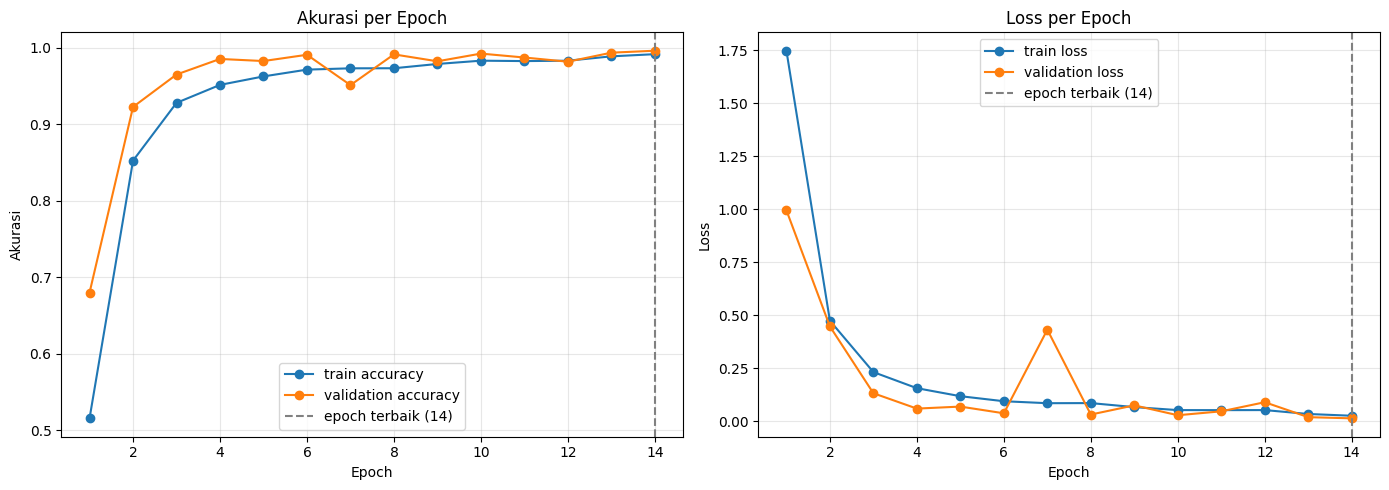

In [17]:
hist = pd.DataFrame(history.history)
hist.index = np.arange(1, len(hist) + 1)
best_epoch = int(hist["val_accuracy"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [(axes[0], "accuracy", "Akurasi"), (axes[1], "loss", "Loss")]:
    ax.plot(hist.index, hist[metric], marker="o", label=f"train {metric}")
    ax.plot(hist.index, hist[f"val_{metric}"], marker="o", label=f"validation {metric}")
    ax.axvline(best_epoch, color="gray", linestyle="--", label=f"epoch terbaik ({best_epoch})")
    ax.set_title(f"{title} per Epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # nomor epoch selalu bilangan bulat
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Akurasi akhir.** Akurasi train pada log training dihitung selama epoch berjalan, saat **augmentasi dan dropout masih aktif** dan bobot masih berubah. Angka itu cenderung lebih rendah daripada kemampuan model yang sebenarnya dan tidak sebanding dengan akurasi test. Supaya perbandingannya adil, akurasi train diukur ulang dengan `evaluate` pada `train_eval_ds` (data train **tanpa augmentasi**), dengan cara yang sama seperti validation dan test.

Hasilnya dicetak sebagai tabel dan baris penanda `TRAIN_ACCURACY`, `VAL_ACCURACY`, dan `TEST_ACCURACY`, diikuti status tercapai atau tidaknya target `TARGET_ACCURACY` pada train dan test.

In [18]:
results = {}
for name, ds in [("train", train_eval_ds), ("validation", val_ds), ("test", test_ds)]:
    loss, acc = best_model.evaluate(ds, verbose=0)
    results[name] = {"loss": loss, "accuracy": acc}
print(pd.DataFrame(results).T.round(4).to_string())

print(f"\nTRAIN_ACCURACY: {results['train']['accuracy']:.4f}")
print(f"VAL_ACCURACY: {results['validation']['accuracy']:.4f}")
print(f"TEST_ACCURACY: {results['test']['accuracy']:.4f}")
target_met = all(results[s]["accuracy"] >= TARGET_ACCURACY for s in ("train", "test"))
print(f"Target >= {TARGET_ACCURACY:.0%} pada train & test: {'TERCAPAI' if target_met else 'BELUM TERCAPAI'}")

              loss  accuracy
train       0.0009    0.9998
validation  0.0148    0.9962
test        0.0580    0.9837

TRAIN_ACCURACY: 0.9998
VAL_ACCURACY: 0.9962
TEST_ACCURACY: 0.9837
Target >= 95% pada train & test: TERCAPAI


**Laporan per kelas dan confusion matrix.** Karena jumlah gambar tiap kelas tidak sama, akurasi keseluruhan saja belum cukup. *Classification report* menampilkan precision, recall, dan F1-score setiap kelas. Confusion matrix (dinormalisasi per label asli) memperlihatkan kelas mana yang paling sering tertukar: semakin gelap diagonalnya, semakin banyak prediksi yang benar.

                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)     1.0000    1.0000    1.0000        60
                              Speed limit (30km/h)     0.9931    0.9986    0.9958       720
                              Speed limit (50km/h)     0.9894    0.9960    0.9927       750
                              Speed limit (60km/h)     1.0000    0.9756    0.9876       450
                              Speed limit (70km/h)     0.9985    0.9924    0.9954       660
                              Speed limit (80km/h)     0.9767    1.0000    0.9882       630
                       End of speed limit (80km/h)     1.0000    1.0000    1.0000       150
                             Speed limit (100km/h)     0.9933    0.9956    0.9945       450
                             Speed limit (120km/h)     0.9978    0.9933    0.9955       450
                                        No passing     0.9717    1.0000    0.98

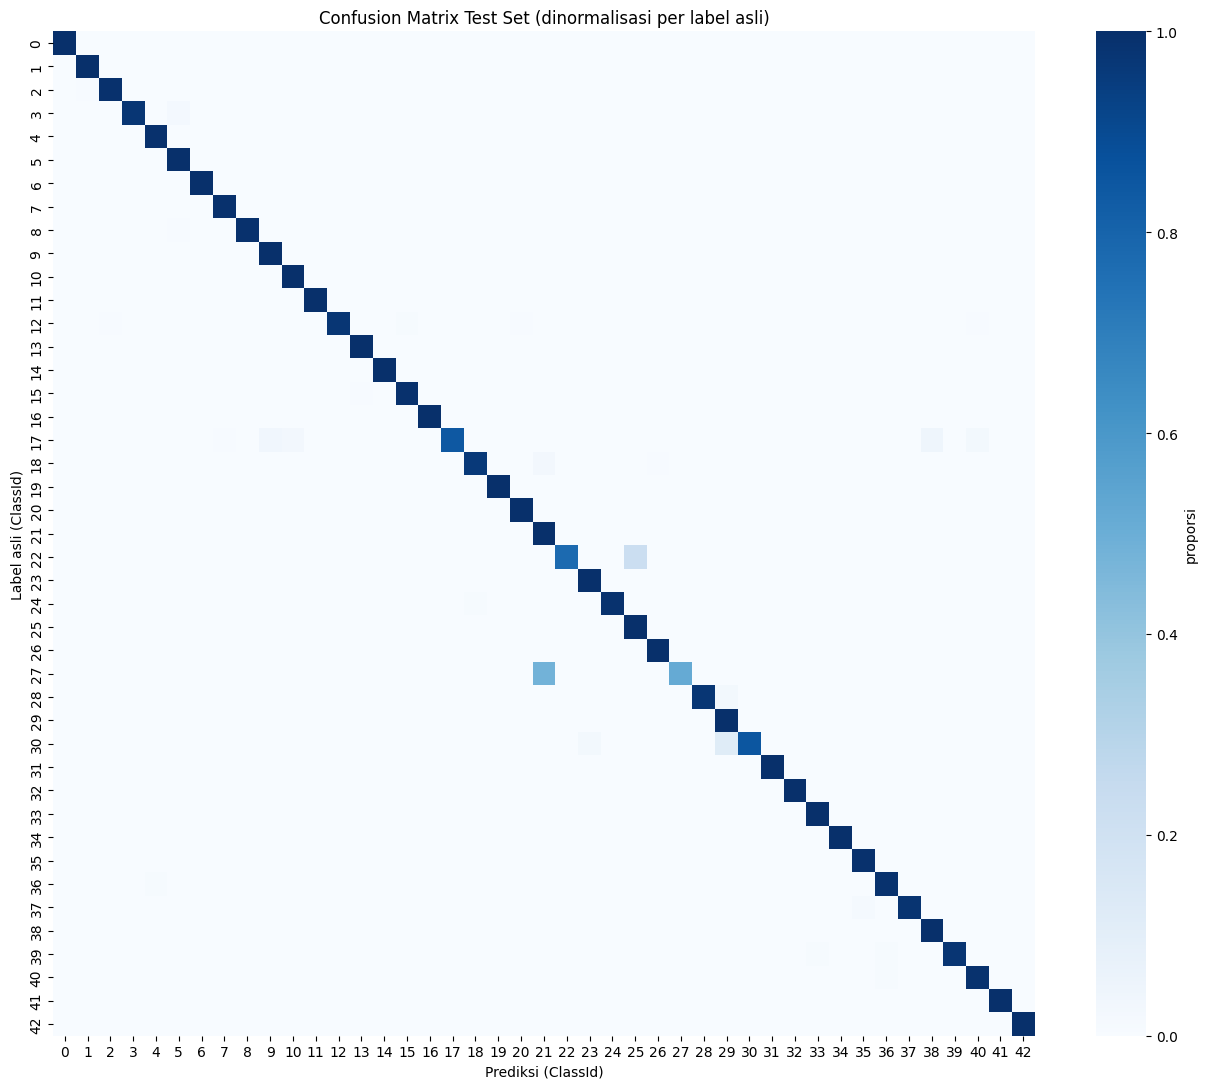

In [19]:
y_true = test_df["label"].values
y_prob = best_model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm, cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "proporsi"})
ax.set_title("Confusion Matrix Test Set (dinormalisasi per label asli)")
ax.set_xlabel("Prediksi (ClassId)")
ax.set_ylabel("Label asli (ClassId)")
plt.tight_layout()
plt.show()

**Interpretasi hasil evaluasi** (angka dari output di atas):
- **Grafik.** Kurva train dan validation naik bersama dan berakhir berdekatan, jadi tidak terlihat tanda overfitting. Epoch terbaik adalah epoch 14.
- **Akurasi akhir.** Train 99,98%, validation 99,62%, dan test 98,37%. Target minimal 95% pada train dan test tercapai. Selisih train dan test hanya 1,61 poin persentase, artinya model menggeneralisasi dengan baik ke data yang belum pernah dilihat.
- **Pengaruh augmentasi pada angka train.** Pada log epoch terakhir akurasi train tercatat 0,9917 (augmentasi dan dropout aktif), sedangkan `evaluate` tanpa augmentasi memberi 0,9998. Inilah alasan akurasi train diukur ulang.
- **Per kelas.** F1-score rata-rata makro 0,9711 dan rata-rata tertimbang 0,9834. Sebanyak 35 dari 43 kelas memiliki F1-score di atas 0,98, tetapi beberapa kelas masih lemah: recall *Pedestrians* 0,5167, *Bumpy road* 0,7750, *No entry* 0,8472, dan *Beware of ice/snow* 0,8533.
- **Confusion matrix.** Kesalahan terbesar ada pada rambu peringatan berbentuk segitiga: *Pedestrians* (27) banyak diprediksi sebagai *Double curve* (21), *Bumpy road* (22) sebagian diprediksi sebagai *Road work* (25), dan *Beware of ice/snow* (30) sebagian diprediksi sebagai *Bicycles crossing* (29). Rambu-rambu ini berbingkai sama dan hanya berbeda pada piktogram kecil di tengahnya, yang sulit dibedakan pada resolusi 48×48 piksel. Perbaikan yang bisa dicoba adalah resolusi input yang lebih besar atau `class_weight` untuk kelas yang datanya sedikit.

## Konversi Model

Model terbaik diekspor ke tiga format supaya bisa dipakai di berbagai platform:
- **SavedModel** di `submission/saved_model/`: format standar TensorFlow, misalnya untuk TensorFlow Serving.
- **TF-Lite** di `submission/tflite/`: `model.tflite` dan `label.txt` untuk perangkat mobile atau embedded.
- **TFJS** di `submission/tfjs_model/`: `model.json` dan file bobot untuk dijalankan di browser.

**1) SavedModel.** Pada Keras 3, SavedModel dibuat dengan `model.export()`, karena `model.save()` hanya mendukung format `.keras` dan `.h5`. Setelah diekspor, model dimuat ulang dan prediksinya dibandingkan dengan model Keras untuk memastikan hasil ekspor benar.

In [20]:
for directory in (SAVED_MODEL_DIR, TFLITE_DIR, TFJS_DIR):
    shutil.rmtree(directory, ignore_errors=True)
SUBMISSION_DIR.mkdir(exist_ok=True)

# 1) SavedModel (Keras 3: model.export, bukan model.save)
best_model.export(str(SAVED_MODEL_DIR))

reloaded = tf.saved_model.load(str(SAVED_MODEL_DIR))
sample_batch, _ = next(iter(test_ds))
same = np.allclose(reloaded.serve(sample_batch).numpy(), best_model.predict(sample_batch, verbose=0), atol=1e-4)
print("Prediksi SavedModel sama dengan model Keras:", same)

Saved artifact at 'submission/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 48, 48, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 43), dtype=tf.float32, name=None)
Captures:
  135005117067152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117066768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117064848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117066960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117065232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117065808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117067344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117068304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117066000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117067536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135005117066384:

**2) TF-Lite.** Model TF-Lite dikonversi dari SavedModel di atas. `label.txt` ditulis dari `CLASS_NAMES` dengan urutan yang sama dengan indeks kelas (baris pertama untuk `ClassId` 0, dan seterusnya), sehingga keluaran model bisa diterjemahkan menjadi nama rambu.

In [21]:
# 2) TF-Lite + label.txt
converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVED_MODEL_DIR))
tflite_model = converter.convert()

TFLITE_DIR.mkdir(parents=True, exist_ok=True)
(TFLITE_DIR / "model.tflite").write_bytes(tflite_model)
(TFLITE_DIR / "label.txt").write_text("\n".join(CLASS_NAMES) + "\n", encoding="utf-8")
print(f"model.tflite: {len(tflite_model) / 1e6:.2f} MB | label.txt: {len(CLASS_NAMES)} kelas")

model.tflite: 5.33 MB | label.txt: 43 kelas


**3) TensorFlow.js.** Konverter TFJS sengaja **tidak dipasang di runtime utama**. Paket `tensorflowjs` 4.22.0 membawa `tensorflow-decision-forests`, yang mengunci `tensorflow==2.19.0`. Memasangnya langsung di sini bisa mengganti versi TensorFlow yang sedang dipakai dan merusak sesi. Karena itu konverter dipasang dan dijalankan di *virtual environment* terpisah yang dibuat dengan `uv`, sehingga runtime utama tidak berubah.

Dua pin tambahan dibutuhkan agar konverter bisa berjalan:
- `ydf==0.12.0`, karena versi `ydf` terbaru memerlukan protobuf 6 sedangkan TensorFlow 2.19 memakai protobuf 5.
- `setuptools<81`, karena `tensorflow_hub` masih mengimpor `pkg_resources`.

Perintah `uv` dijalankan tanpa variabel lingkungan `UV_*` milik runtime utama. Di Google Colab, variabel seperti `UV_CONSTRAINT` dan `UV_SYSTEM_PYTHON` dapat terpasang untuk mengatur Python utama, sehingga tidak boleh ikut mengatur venv konverter. Dengan begitu isi venv hanya ditentukan oleh pin di atas.

Opsi `--weight_shard_size_bytes` diperbesar supaya seluruh bobot tersimpan dalam satu file `group1-shard1of1.bin`.

In [22]:
# 3) TensorFlow.js
# tensorflowjs 4.22 menarik tensorflow-decision-forests yang mengunci tensorflow==2.19. Menginstalnya
# langsung di runtime ini bisa mengganti versi TensorFlow yang sedang dipakai, jadi konverter
# dijalankan di virtual environment terpisah. Dua pin tambahan diperlukan agar konverter bisa jalan:
#   - ydf==0.12.0     : ydf terbaru butuh protobuf 6, sedangkan tensorflow 2.19 memakai protobuf 5
#   - setuptools<81   : tensorflow_hub masih mengimpor pkg_resources
def run_command(cmd, env=None) -> str:
    """Jalankan perintah shell; tampilkan output bila gagal lalu hentikan notebook."""
    cmd = [str(c) for c in cmd]
    print("$", " ".join(cmd))
    result = subprocess.run(cmd, capture_output=True, text=True, env=env)
    if result.returncode != 0:
        print((result.stdout + result.stderr)[-5000:])
        raise RuntimeError(f"Perintah gagal (exit code {result.returncode})")
    return result.stdout


TFJS_ENV = Path("/content/tfjs_env") if IN_COLAB else Path(".tfjs_env").resolve()
tfjs_converter = TFJS_ENV / "bin" / "tensorflowjs_converter"

if not tfjs_converter.exists():
    if shutil.which("uv"):
        uv = [shutil.which("uv")]
    else:
        run_command([sys.executable, "-m", "pip", "install", "-q", "uv"])
        uv = [sys.executable, "-m", "uv"]
    # Variabel UV_* milik runtime utama (mis. UV_CONSTRAINT dan UV_SYSTEM_PYTHON di Colab) tidak diteruskan
    # ke uv, supaya venv konverter dibuat dengan konfigurasi bawaan dan hanya mengikuti pin di bawah
    uv_env = {key: value for key, value in os.environ.items() if not key.startswith("UV_")}
    shutil.rmtree(TFJS_ENV, ignore_errors=True)
    run_command(uv + ["venv", "--python", "3.12", TFJS_ENV], env=uv_env)
    run_command(uv + ["pip", "install", "--python", TFJS_ENV / "bin" / "python",
                      "tensorflowjs==4.22.0", "ydf==0.12.0", "setuptools<81"], env=uv_env)

converter_env = {**os.environ, "CUDA_VISIBLE_DEVICES": "-1", "TF_CPP_MIN_LOG_LEVEL": "3"}
run_command([tfjs_converter,
             "--input_format=tf_saved_model",
             "--output_format=tfjs_graph_model",
             "--signature_name=serving_default",
             "--saved_model_tags=serve",
             "--weight_shard_size_bytes=67108864",   # satu file shard: group1-shard1of1.bin
             SAVED_MODEL_DIR, TFJS_DIR], env=converter_env)

for f in sorted(TFJS_DIR.iterdir()):
    print(f"  {f.name:<26} {f.stat().st_size / 1e6:.2f} MB")

$ /usr/local/bin/uv venv --python 3.12 /content/tfjs_env
$ /usr/local/bin/uv pip install --python /content/tfjs_env/bin/python tensorflowjs==4.22.0 ydf==0.12.0 setuptools<81
$ /content/tfjs_env/bin/tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model --signature_name=serving_default --saved_model_tags=serve --weight_shard_size_bytes=67108864 submission/saved_model submission/tfjs_model
  group1-shard1of1.bin       5.33 MB
  model.json                 0.02 MB


**4) `requirements.txt` dan isi folder submission.** `requirements.txt` ditulis dari versi library yang benar-benar terpasang saat notebook dijalankan, bukan diketik manual, sehingga lingkungannya dapat dibuat ulang dengan tepat. Sel terakhir menampilkan isi folder `submission/` dan, khusus di Google Colab, mengemas seluruh artefak menjadi `hasil_colab_artifacts.zip` lalu mengunduhnya.

In [23]:
# 4) requirements.txt berisi versi library yang benar-benar dipakai saat notebook dijalankan
packages = ["tensorflow", "keras", "numpy", "pandas", "matplotlib", "seaborn",
            "scikit-learn", "pillow", "kagglehub", "ai-edge-litert"]
lines = []
for package in packages:
    try:
        lines.append(f"{package}=={importlib_metadata.version(package)}")
    except importlib_metadata.PackageNotFoundError:
        pass
lines += ["", "# Konversi TFJS dijalankan di virtual environment terpisah (lihat bagian Konversi Model):",
          "# tensorflowjs==4.22.0 ydf==0.12.0 setuptools<81  (otomatis memakai tensorflow==2.19.0)"]
(SUBMISSION_DIR / "requirements.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")
print((SUBMISSION_DIR / "requirements.txt").read_text())

tensorflow==2.21.0
keras==3.13.2
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
pillow==11.3.0
kagglehub==1.0.3

# Konversi TFJS dijalankan di virtual environment terpisah (lihat bagian Konversi Model):
# tensorflowjs==4.22.0 ydf==0.12.0 setuptools<81  (otomatis memakai tensorflow==2.19.0)



In [24]:
print("Isi folder submission:")
for path in sorted(SUBMISSION_DIR.rglob("*")):
    depth = len(path.relative_to(SUBMISSION_DIR).parts) - 1
    size = f"({path.stat().st_size / 1e6:.2f} MB)" if path.is_file() else ""
    print(f"{'    ' * depth}{path.name}{'/' if path.is_dir() else ''} {size}")

if IN_COLAB:   # unduh semua artefak model sekaligus untuk dibawa ke folder proyek lokal
    from google.colab import files
    archive = shutil.make_archive("hasil_colab_artifacts", "zip", root_dir=".", base_dir=SUBMISSION_DIR.name)
    files.download(archive)

Isi folder submission:
requirements.txt (0.00 MB)
saved_model/ 
    assets/ 
    fingerprint.pb (0.00 MB)
    saved_model.pb (0.24 MB)
    variables/ 
        variables.data-00000-of-00001 (10.67 MB)
        variables.index (0.00 MB)
tfjs_model/ 
    group1-shard1of1.bin (5.33 MB)
    model.json (0.02 MB)
tflite/ 
    label.txt (0.00 MB)
    model.tflite (5.33 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Hasil konversi** (lihat output di atas): prediksi SavedModel sama dengan model Keras, `model.tflite` berukuran 5,33 MB dengan `label.txt` berisi 43 kelas, dan model TFJS terdiri atas `model.json` (0,02 MB) serta satu file bobot `group1-shard1of1.bin` (5,33 MB). Ketiga format tersimpan di folder `submission/`.

## Inference (Optional)

Bagian ini membuktikan bahwa model hasil konversi benar-benar bisa dipakai. Model **TF-Lite** dimuat dengan interpreter LiteRT (penerus `tf.lite.Interpreter`). Jika paket LiteRT tidak tersedia, notebook otomatis memakai `tf.lite.Interpreter`.

**Akurasi TF-Lite pada seluruh test set.** Model TF-Lite menerima input yang sama dengan model Keras, yaitu piksel mentah 0–255, karena normalisasi sudah ada di dalam model. Prediksinya dihitung untuk seluruh test set, lalu dibandingkan dengan label asli dan dengan prediksi model Keras.

In [25]:
try:
    from ai_edge_litert.interpreter import Interpreter   # LiteRT, penerus tf.lite.Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter

interpreter = Interpreter(model_path=str(TFLITE_DIR / "model.tflite"))
input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]
tflite_labels = (TFLITE_DIR / "label.txt").read_text(encoding="utf-8").splitlines()
print("Input :", input_detail["shape"], input_detail["dtype"].__name__)
print("Output:", output_detail["shape"], output_detail["dtype"].__name__)


def predict_tflite(batch: np.ndarray) -> np.ndarray:
    """Prediksi satu batch gambar (float32, 0-255, IMG_SIZE x IMG_SIZE) dengan model TF-Lite."""
    interpreter.resize_tensor_input(input_detail["index"], batch.shape)
    interpreter.allocate_tensors()
    interpreter.set_tensor(input_detail["index"], batch.astype(np.float32))
    interpreter.invoke()
    return interpreter.get_tensor(output_detail["index"])


tflite_pred = np.concatenate([predict_tflite(x.numpy()).argmax(axis=1) for x, _ in test_ds])
print(f"TFLITE_TEST_ACCURACY: {(tflite_pred == y_true).mean():.4f}")
print(f"Prediksi TF-Lite sama dengan model Keras: {(tflite_pred == y_pred).mean():.2%}")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Input : [ 1 48 48  3] float32
Output: [ 1 43] float32
TFLITE_TEST_ACCURACY: 0.9837
Prediksi TF-Lite sama dengan model Keras: 100.00%


**Hasil.** Akurasi model TF-Lite pada seluruh test set (12.630 gambar) adalah 98,37% (`TFLITE_TEST_ACCURACY: 0.9837`), dan 100% prediksinya sama dengan model Keras. Artinya konversi tidak mengubah perilaku model. Peringatan *deprecated* pada output muncul karena paket LiteRT tidak terpasang di runtime ini, sehingga dipakai `tf.lite.Interpreter`. Hasilnya tidak terpengaruh.

**Prediksi pada gambar test.** Fungsi `predict_image_file` menerima satu file gambar mentah dengan resolusi berapa pun, menjalankan preprocessing yang sama dengan saat training, lalu memprediksinya dengan model TF-Lite. Dua belas gambar test dipilih acak dan ditampilkan bersama label asli, hasil prediksi, dan tingkat keyakinan model. Judul berwarna hijau berarti prediksi benar, merah berarti salah.

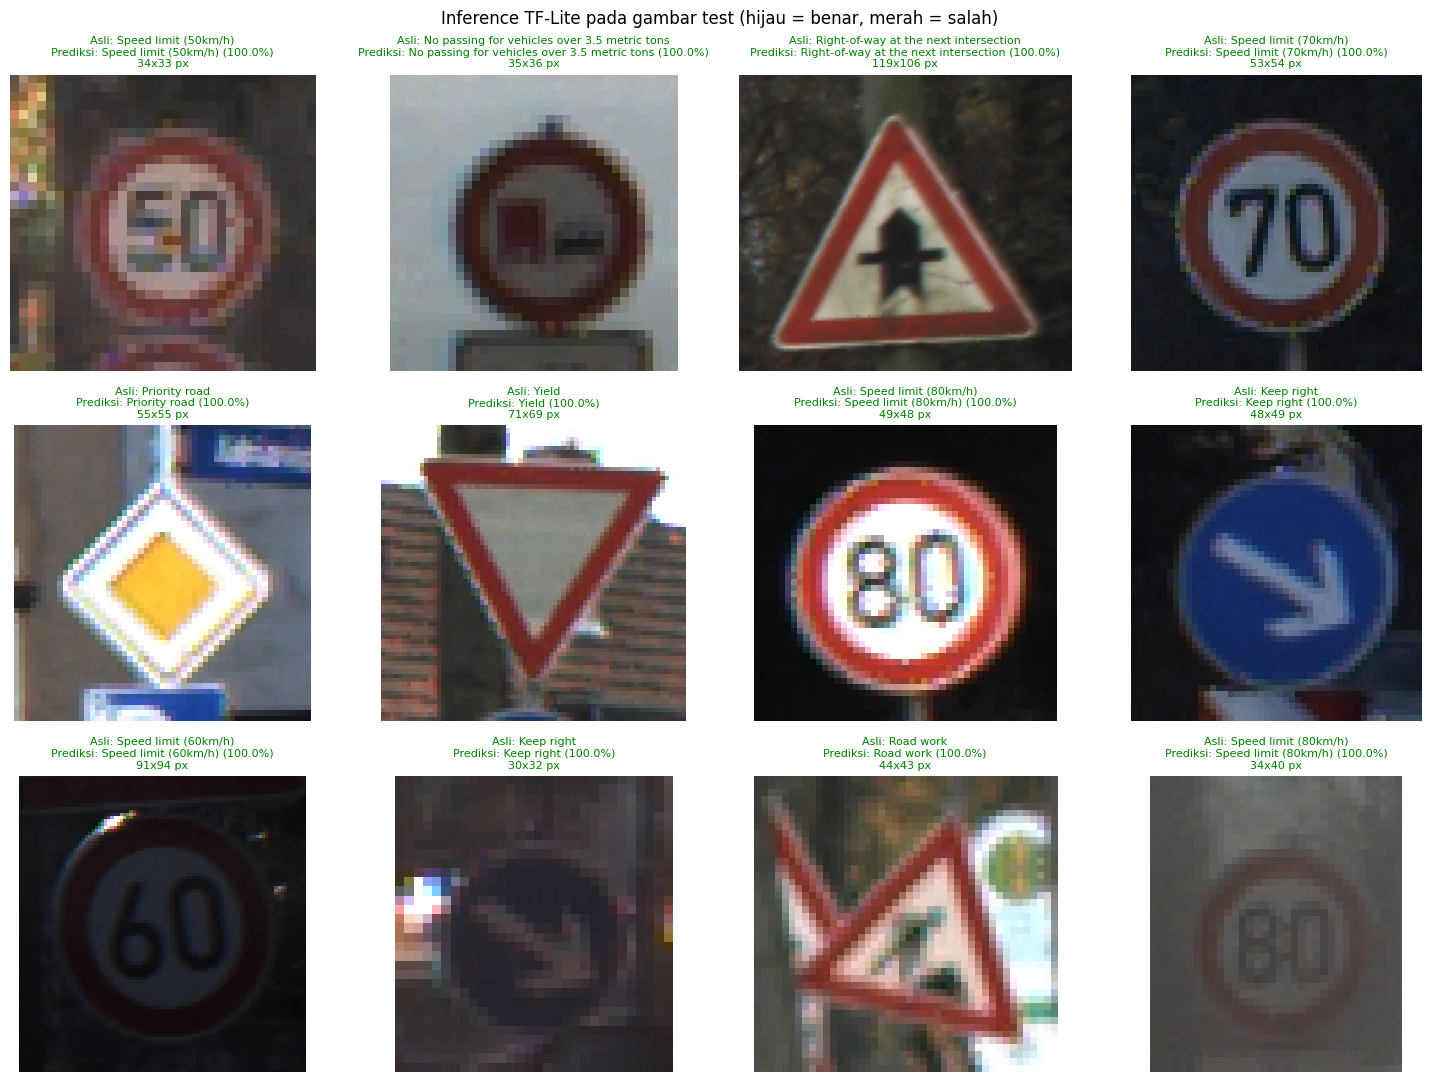

In [26]:
def predict_image_file(path: str):
    """Prediksi satu file gambar mentah (resolusi berapa pun) dengan model TF-Lite."""
    image = load_and_resize(tf.constant(path)).numpy().astype(np.float32)[None, ...]
    probs = predict_tflite(image)[0]
    return int(probs.argmax()), float(probs.max())


demo = test_df.sample(12, random_state=SEED)
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for ax, (_, row) in zip(axes.flat, demo.iterrows()):
    pred, conf = predict_image_file(row["path"])
    with Image.open(row["path"]) as img:
        ax.imshow(img)
        size = img.size
    ax.set_title(f"Asli: {tflite_labels[row['label']]}\n"
                 f"Prediksi: {tflite_labels[pred]} ({conf:.1%})\n"
                 f"{size[0]}x{size[1]} px",
                 color="green" if pred == row["label"] else "red", fontsize=8)
    ax.axis("off")
plt.suptitle("Inference TF-Lite pada gambar test (hijau = benar, merah = salah)")
plt.tight_layout()
plt.show()

**Hasil.** Kedua belas gambar contoh diprediksi dengan benar (semua judul berwarna hijau, dengan tingkat keyakinan tercetak 100,0%), padahal resolusi aslinya beragam, dari 30×32 px sampai 119×106 px, dan beberapa di antaranya gelap atau buram.

**Kesimpulan.** CNN `Sequential` dengan 1.332.683 parameter berhasil mengklasifikasikan 43 kelas rambu lalu lintas GTSRB dengan akurasi **99,98% pada train, 99,62% pada validation, dan 98,37% pada test**, sehingga target minimal 95% tercapai. Training berhenti otomatis pada epoch 14 dari maksimal 30. Model sudah diekspor ke SavedModel, TF-Lite, dan TFJS, dan model TF-Lite menghasilkan akurasi test yang sama (98,37%) dengan prediksi yang 100% identik dengan model Keras. Kelemahan yang tersisa ada pada beberapa rambu peringatan berbentuk segitiga, terutama *Pedestrians* (recall 0,5167), yang bisa menjadi fokus perbaikan berikutnya.